## Analyze Corpus Due 22-NOV
This is the next step in your Portfolio Project started in the Create a Corpus assignment. This assignment should be done in the same groups. 

1. Import and preprocess your corpus.

In [1]:
# core libraries 
import os
import numpy as np
import pandas as pd

# plots
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from scipy.cluster.hierarchy import dendrogram, linkage

# modeling and stats
from numpy.linalg import norm
import statsmodels.formula.api as smf
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import cosine_similarity
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr
from scipy.cluster.hierarchy import linkage, dendrogram
from skbio.stats.distance import mantel 
from skbio.stats.distance import DistanceMatrix

# embeddings and transformers
import torch
from transformers import AutoTokenizer, AutoModel

# networks
import networkx as nx
import community as community_louvain  # python-louvain
import umap

# reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

sns.set(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300

/Users/addieclark/Library/jupyterlab-desktop/envs/pd_np_mp/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# LLM Surprisal Corpus 

The LM corpus contains, for each target–cue pair and context frame:

- target_word_unique — predicted word
- cue_word_related, cue_word_unrelated — primes
- model — one of gpt2, bloom-560m, roberta-base
- surprisal_A — surprisal of target given related cue context
- surprisal_B — surprisal of target given unrelated cue context
- priming_delta = surprisal_B - surprisal_A

# note to self 
Positive priming_delta indicates human-like priming (target more expected after related cue).

In [2]:
lm_df = pd.read_csv("corpus_w_surprisals.csv")
print(lm_df.head())
print("\nModels in corpus:", lm_df["model"].unique())

# Sanity check shape
print("LM corpus shape:", lm_df.shape)

   pair_id   context target_word_unique cue_word_related cue_word_unrelated  \
0        1  context1            abandon            leave              dirty   
1        2  context1          abdominal           spinal           chemical   
2        3  context1             abduct           kidnap             trophy   
3        4  context1            ability         capacity          briefcase   
4        5  context1              about              out               bone   

  last_word_A last_word_B model  surprisal_A  surprisal_B  priming_delta  
0     abandon     abandon  gpt2    16.444321    17.771625       1.327304  
1   abdominal   abdominal  gpt2    12.113892    16.875096       4.761203  
2      abduct      abduct  gpt2     9.819173    18.358790       8.539617  
3     ability     ability  gpt2    14.129741    16.326720       2.196979  
4       about       about  gpt2     8.673937     8.705705       0.031768  

Models in corpus: ['gpt2' 'bloom-560m' 'roberta-base']
LM corpus shape: (1

# human priming data (`en_prime`)

The human priming file contains aggregated reaction-time (RT) and accuracy statistics per target word, including:

- `avgRT_related`, `avgRT_unrelated`
- `avgZ_RT_related`, `avgZ_RT_unrelated`
- accuracy proportions and sample sizes

A human priming delta was constructed to be analogous to the LM measure using Z-scored RTs

# note to self 
Positive values mean faster (lower Z) after related prime.

In [3]:
human_df = pd.read_csv("../../data/item_data/en/en_item_data.csv")
print("Human priming columns:\n", human_df.columns.tolist())
print("Human data shape:", human_df.shape)

# build dictionary, target : (related, unrelated)
pairs = {}

for _, row in lm_df.iterrows():
    t = row["target_word_unique"]
    r = row["cue_word_related"]
    u = row["cue_word_unrelated"]

    if t not in pairs:
        pairs[t] = {"related": set(), "unrelated": set()}

    pairs[t]["related"].add(r)
    pairs[t]["unrelated"].add(u)

# make lookup for human lexical difficulty
human_map = dict(zip(human_df["word"], human_df["avgZ_RT"]))

# create output lists
targets = []
human_rel = []
human_unrel = []
human_delta = []

# construct human related/unrelated RTs per target
for t, info in pairs.items():
    rel_set = info["related"]
    unrel_set = info["unrelated"]

    # get human RTs for all related cues
    rel_vals = [human_map[w] for w in rel_set if w in human_map]
    unrel_vals = [human_map[w] for w in unrel_set if w in human_map]

    if len(rel_vals) == 0 or len(unrel_vals) == 0:
        # skip targets without human data for both cue types
        continue

    human_rel_val = np.mean(rel_vals)
    human_unrel_val = np.mean(unrel_vals)
    delta = human_unrel_val - human_rel_val   # human priming_delta

    targets.append(t)
    human_rel.append(human_rel_val)
    human_unrel.append(human_unrel_val)
    human_delta.append(delta)

# clean the DataFrame    
human_prime = pd.DataFrame({
    "target_word_unique": targets,
    "human_avgZ_RT_related": human_rel,
    "human_avgZ_RT_unrelated": human_unrel,
    "human_priming_delta": human_delta
})

print("Constructed human priming dataset:", human_prime.shape)
human_prime.head()

Human priming columns:
 ['word', 'class', 'avgRT', 'avgZ_RT', 'samplesize', 'n_answered', 'seRT', 'seZ_RT', 'accuracy', 'Z2.5_avgRT', 'Z2.5_avgZ_RT', 'Z2.5_samplesize', 'Z2.5_n_answered', 'Z2.5_seRT', 'Z2.5_seZ_RT', 'Z2.5_accuracy', 'Z3.0_avgRT', 'Z3.0_avgZ_RT', 'Z3.0_samplesize', 'Z3.0_n_answered', 'Z3.0_seRT', 'Z3.0_seZ_RT', 'Z3.0_accuracy']
Human data shape: (3978, 23)
Constructed human priming dataset: (1000, 4)


,target_word_unique,human_avgZ_RT_related,human_avgZ_RT_unrelated,human_priming_delta
0,abandon,-0.304426,-0.275125,0.029301
1,abdominal,0.127429,-0.278340,-0.405768
2,abduct,-0.143333,-0.018975,0.124357
3,ability,-0.169335,0.184335,0.353670
4,about,-0.258376,-0.282074,-0.023699


2. Conduct the analysis you proposed in the last Preprocess and Visualize assignment. This should include both the modeling itself and visualizations of the output. 

**Suggestions from Preprocess and Visualize assignment**
- Network or cluster analysis might be interesting here to determine words pairs cluster in interesting ways based on surprisal, priming, and/or embeddings.
- Calculating the similarity between the word embedding vectors of the target and cue words for the different models then compare the similarity to the surprisal and priming values.
- Network models + cluster analysis based on the word pairs and their embedding similarities

In [4]:
# define cosine similarity 
def cosine_sim(a: np.ndarray, b: np.ndarray) -> float:
    """Cosine similarity between two 1D numpy vectors."""
    return float(np.dot(a, b) / (norm(a) * norm(b)))   

# embedding 
- tokenizes a single word,
- runs a forward pass with gradients disabled,
- mean-pools token representations into one vector.

In [5]:
def get_word_embedding(model, tokenizer, word):
    tokens = tokenizer(word, return_tensors='pt')
    with torch.no_grad():
        out = model(**tokens)
    # Mean pooling across tokens
    return out.last_hidden_state.mean(dim=1).squeeze().numpy()

def get_word_embedding(model, tokenizer, word: str) -> np.ndarray:
    """Compute a mean-pooled embedding for a single word string.

    Parameters
    ----------
    model : transformers.AutoModel
    tokenizer : transformers.AutoTokenizer
    word : str

    Returns
    -------
    np.ndarray
        1D embedding vector.
    """
    encoded = tokenizer(word, return_tensors="pt")
    with torch.no_grad():
        out = model(**encoded)
    # mean pool over token dimension
    vec = out.last_hidden_state.mean(dim=1).squeeze().cpu().numpy()
    return vec    

# note to self 
aggregate the LM corpus at the target-word and model level, averaging priming across contexts and cue pairs, then join with the human data.

In [6]:
# aggregate LM priming by target + model
lm_item = (
    lm_df
    .groupby(["target_word_unique", "model"], as_index=False)
    .agg({
        "priming_delta": "mean",
        "surprisal_A": "mean",
        "surprisal_B": "mean"
    })
    .rename(columns={"priming_delta": "lm_priming_delta"})
)

print("Aggregated LM item-level data:")
print(lm_item.head())

# merge with human data on target_word_unique
merged_item = lm_item.merge(human_prime, on="target_word_unique", how="inner")
print("Merged LM + human shape:", merged_item.shape)

merged_item[[
    "target_word_unique", "model",
    "lm_priming_delta",
    "human_avgZ_RT_related",
    "human_avgZ_RT_unrelated",
    "human_priming_delta"
]].head()

Aggregated LM item-level data:
  target_word_unique         model  lm_priming_delta  surprisal_A  surprisal_B
0            abandon    bloom-560m          5.693033    12.035088    17.728121
1            abandon          gpt2          3.053427    14.218260    17.271688
2            abandon  roberta-base          1.183520    57.692079    58.875599
3          abdominal    bloom-560m          8.911257     7.955541    16.866798
4          abdominal          gpt2          5.514149    10.603774    16.117922
Merged LM + human shape: (3000, 8)


,target_word_unique,model,lm_priming_delta,human_avgZ_RT_related,human_avgZ_RT_unrelated,human_priming_delta
0,abandon,bloom-560m,5.693033,-0.304426,-0.275125,0.029301
1,abandon,gpt2,3.053427,-0.304426,-0.275125,0.029301
2,abandon,roberta-base,1.183520,-0.304426,-0.275125,0.029301
3,abdominal,bloom-560m,8.911257,0.127429,-0.278340,-0.405768
4,abdominal,gpt2,5.514149,0.127429,-0.278340,-0.405768


# descriptive stats for surprise and priming 
- examine the distributions of surprisal and priming deltas

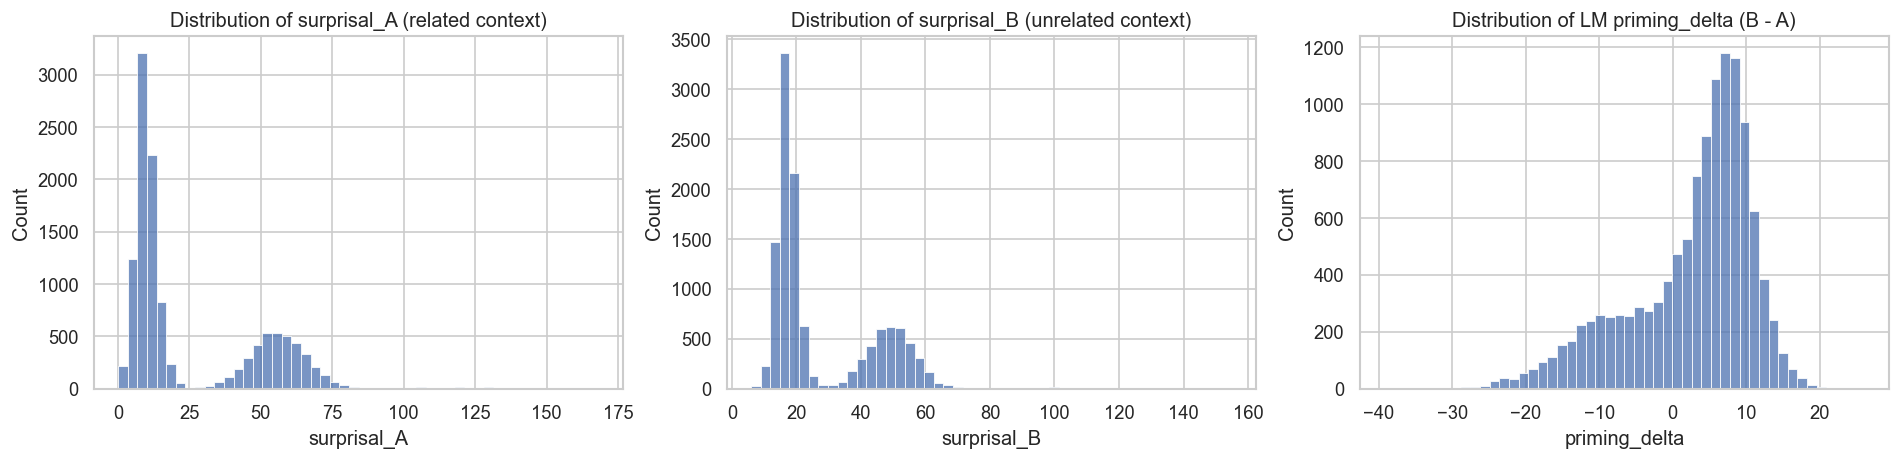

Models: ['gpt2' 'bloom-560m' 'roberta-base']


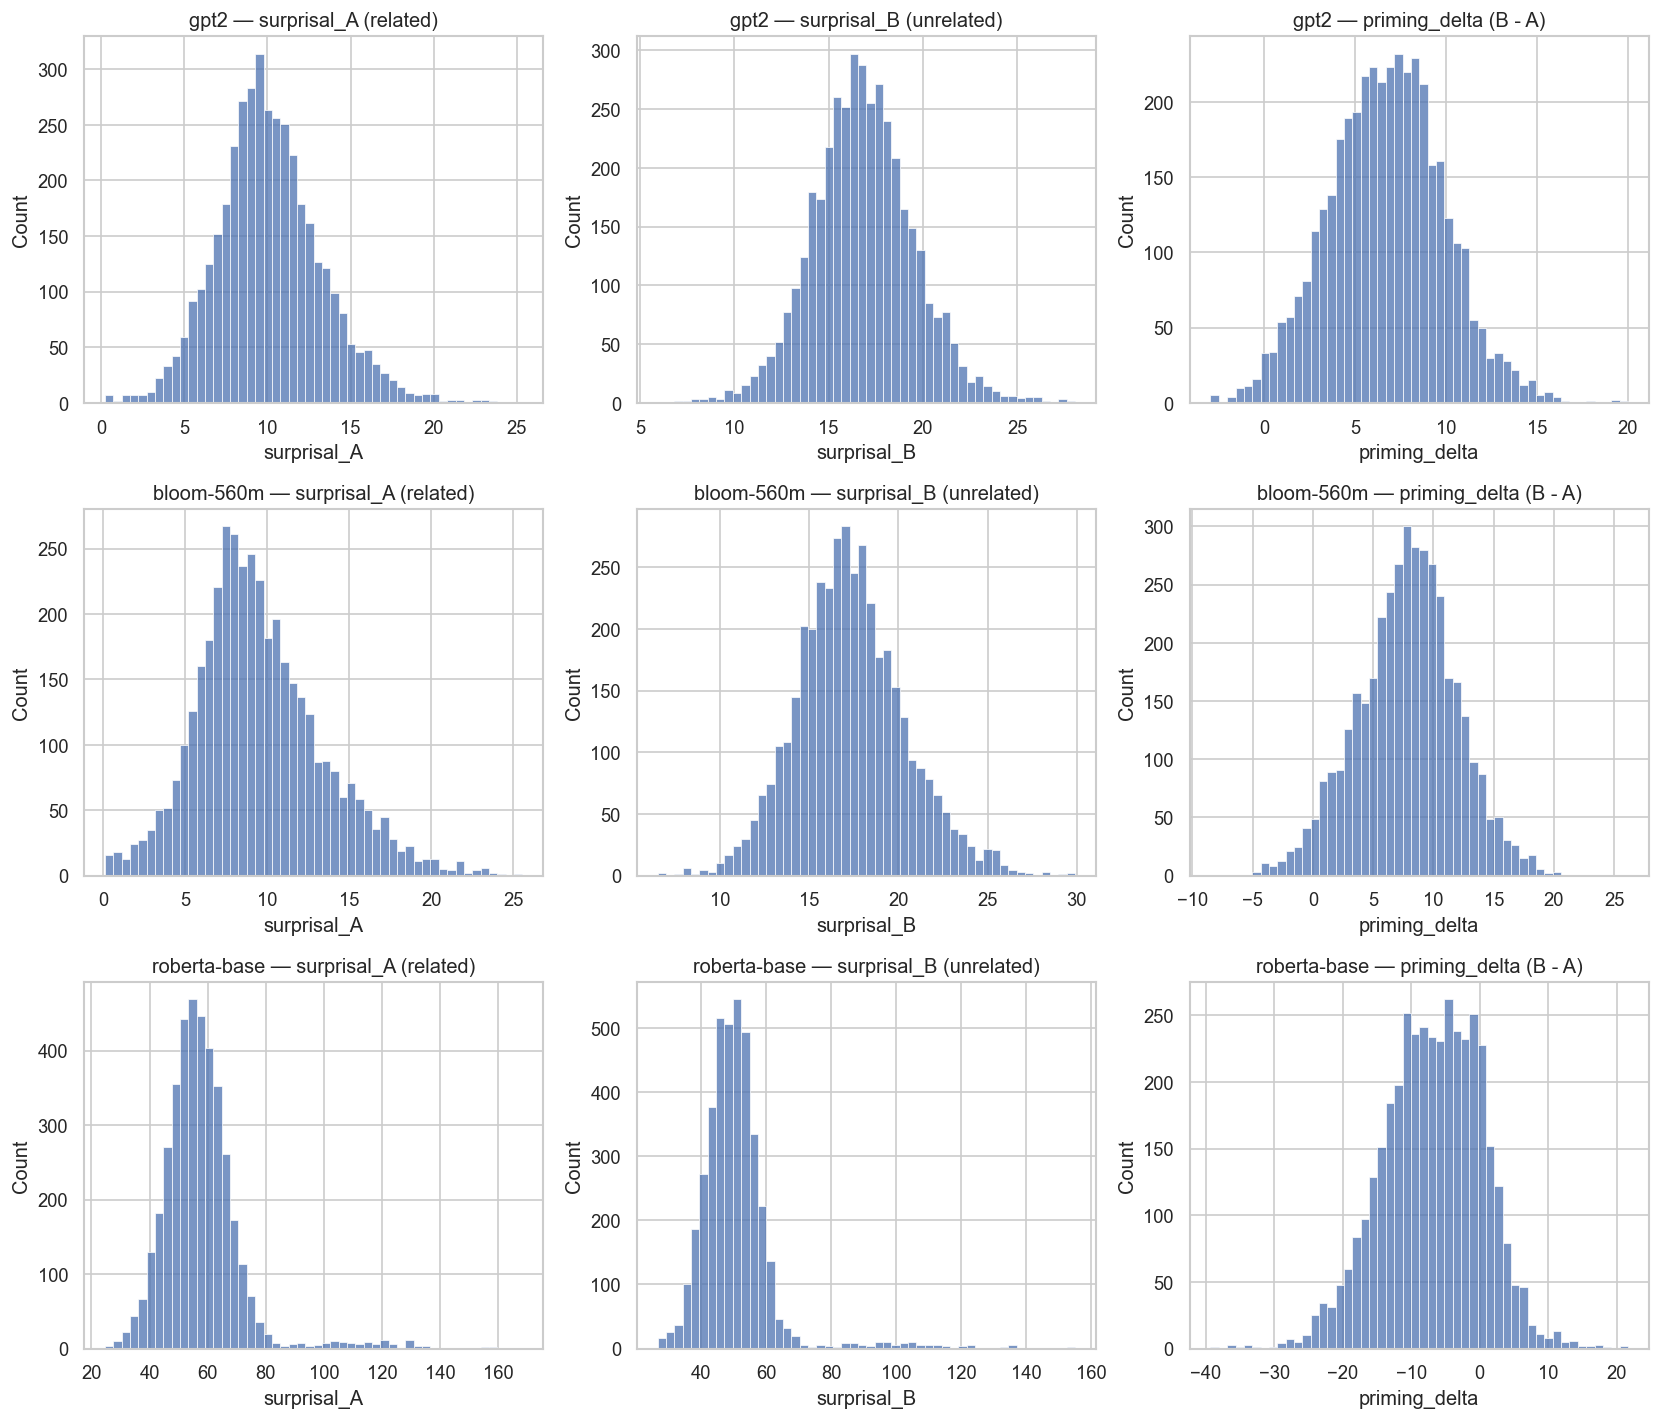

In [7]:
# LM priming distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(lm_df["surprisal_A"], bins=50, ax=axes[0])
axes[0].set_title("Distribution of surprisal_A (related context)")

sns.histplot(lm_df["surprisal_B"], bins=50, ax=axes[1])
axes[1].set_title("Distribution of surprisal_B (unrelated context)")

sns.histplot(lm_df["priming_delta"], bins=50, ax=axes[2])
axes[2].set_title("Distribution of LM priming_delta (B - A)")

plt.tight_layout()
plt.show()

lm_models = lm_df["model"].unique()
print("Models:", lm_models)

fig, axes = plt.subplots(len(lm_models), 3, figsize=(14, 4 * len(lm_models)))

for i, m in enumerate(lm_models):
    sub = lm_df[lm_df["model"] == m]

    # Surprisal A
    sns.histplot(sub["surprisal_A"], bins=50, ax=axes[i, 0])
    axes[i, 0].set_title(f"{m} — surprisal_A (related)")

    # Surprisal B
    sns.histplot(sub["surprisal_B"], bins=50, ax=axes[i, 1])
    axes[i, 1].set_title(f"{m} — surprisal_B (unrelated)")

    # Priming delta
    sns.histplot(sub["priming_delta"], bins=50, ax=axes[i, 2])
    axes[i, 2].set_title(f"{m} — priming_delta (B - A)")

plt.tight_layout()
plt.show()

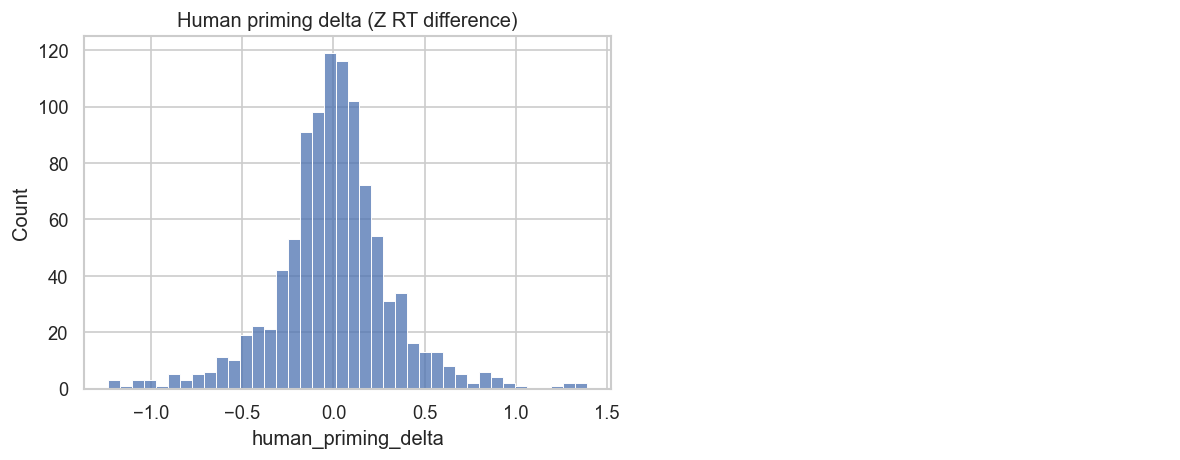

In [8]:
# human priming distributions
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.histplot(human_prime["human_priming_delta"], bins=40, ax=axes[0])
axes[0].set_title("Human priming delta (Z RT difference)")
axes[1].axis("off")  # hide the second panel if no RT version exists

plt.tight_layout()
plt.show()

In [9]:
# Merge human priming data into lm_df on target_word_unique
lm_df = lm_df.merge(human_prime, on="target_word_unique", how="left")

print("New lm_df shape:", lm_df.shape)
lm_df.head()

import pandas as pd

# Variables we want to summarize
vars_to_summarize = [
    "surprisal_A",
    "surprisal_B",
    "priming_delta",
    "human_priming_delta",
    "gpt2_sim_diff",
    "bloom_sim_diff",
    "roberta_sim_diff"
]

# Restrict to variables that actually exist
existing_vars = [v for v in vars_to_summarize if v in lm_df.columns]

print("Using variables:", existing_vars)

# Compute descriptive statistics
desc_table = lm_df[existing_vars].describe().T

# Rename columns for readability
desc_table = desc_table.rename(columns={
    "count": "N",
    "mean": "Mean",
    "std": "SD",
    "min": "Min",
    "25%": "Q1",
    "50%": "Median",
    "75%": "Q3",
    "max": "Max"
}).round(3)

desc_table

New lm_df shape: (12000, 14)
Using variables: ['surprisal_A', 'surprisal_B', 'priming_delta', 'human_priming_delta']


,N,Mean,SD,Min,Q1,Median,Q3,Max
surprisal_A,12000.0,25.808,24.201,0.091,8.534,11.868,49.908,168.365
surprisal_B,12000.0,28.339,17.600,5.937,16.132,18.801,44.581,154.994
priming_delta,12000.0,2.532,8.457,-39.293,-1.845,5.011,8.455,26.134
human_priming_delta,12000.0,-0.000,0.319,-1.237,-0.155,0.001,0.153,1.391


# description of LM priming deltas and human priming deltas 
- Are LM priming deltas near zero?
    - Language models do not exhibit robust human-like priming effects. Whatever semantic advantages related primes provide in embedding space do not translate into meaningful reductions in surprisal.
- Are LM priming deltas centered?
    - Although the effects are small, LM priming is not neutral — each model exhibits a directionally biased but still extremely weak priming/anti-priming profile.
    - GPT-2 and BLOOM-560M show a slight positive shift, meaning surprisal is marginally higher for unrelated contexts.
    - RoBERTa shows a slight negative shift, indicating the opposite pattern.
- These shifts are small but systematic. Each model has its own characteristic bias in how it handles context-driven expectancy.
- Are human priming deltas positive?
    - Human priming is real but modest, and highly item-dependent. The distribution reflects a meaningful, positive priming effect on average—but with widespread variability that LMs fail to capture.

# Embedding extractions 

In [10]:
# load models
models = {
    "gpt2": "gpt2",
    "bloom": "bigscience/bloom-560m",
    "roberta": "roberta-base"
}

# Load tokenizers and models
embed_tokenizers = {}
embed_models = {}

for name, path in models.items():
    print(f"Loading {name} from {path}...")
    embed_tokenizers[name] = AutoTokenizer.from_pretrained(path)
    embed_models[name] = AutoModel.from_pretrained(path)


Loading gpt2 from gpt2...
Loading bloom from bigscience/bloom-560m...
Loading roberta from roberta-base...


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


# compute embeddings 
- once per unique word (targets and cues) then reuse them when building similarities.

In [11]:
# compute embeddings for each model 

unique_targets = lm_df["target_word_unique"].unique().tolist()
unique_cues_rel = lm_df["cue_word_related"].unique().tolist()
unique_cues_unrel = lm_df["cue_word_unrelated"].unique().tolist()

all_words = sorted(set(unique_targets) | set(unique_cues_rel) | set(unique_cues_unrel))
print("Total unique words for embedding:", len(all_words))

# Dictionary: model_name -> {word -> vector}
embeddings = {name: {} for name in models.keys()}

for name in models.keys():
    print(f"Computing embeddings for {name}...")
    tok = embed_tokenizers[name]
    mod = embed_models[name]
    cache = {}
    for w in all_words:
        cache[w] = get_word_embedding(mod, tok, w)
    embeddings[name] = cache

Total unique words for embedding: 1999
Computing embeddings for gpt2...
Computing embeddings for bloom...
Computing embeddings for roberta...


# cosine similarity: related vs unrelated
- `*_sim_related` — cosine(target, related cue)
- `*_sim_unrelated` — cosine(target, unrelated cue)
- `*_sim_diff` = related − unrelated

In [12]:
# compute cosine similiarity for each model 
lm_df = lm_df.copy()
for name in models.keys():
    print(f"Computing cosine similarity for {name}...")
    emb = embeddings[name]

    lm_df[f"{name}_sim_related"] = lm_df.apply(
        lambda row: cosine_sim(
            emb[row["target_word_unique"]],
            emb[row["cue_word_related"]]
        ),
        axis=1
    )

    lm_df[f"{name}_sim_unrelated"] = lm_df.apply(
        lambda row: cosine_sim(
            emb[row["target_word_unique"]],
            emb[row["cue_word_unrelated"]]
        ),
        axis=1
    )

    lm_df[f"{name}_sim_diff"] = (
        lm_df[f"{name}_sim_related"] - lm_df[f"{name}_sim_unrelated"]
    )

lm_df.head()

Computing cosine similarity for gpt2...
Computing cosine similarity for bloom...
Computing cosine similarity for roberta...


,pair_id,context,target_word_unique,cue_word_related,cue_word_unrelated,last_word_A,last_word_B,model,surprisal_A,surprisal_B,...,human_priming_delta,gpt2_sim_related,gpt2_sim_unrelated,gpt2_sim_diff,bloom_sim_related,bloom_sim_unrelated,bloom_sim_diff,roberta_sim_related,roberta_sim_unrelated,roberta_sim_diff
0,1,context1,abandon,leave,dirty,abandon,abandon,gpt2,16.444321,17.771625,...,0.029301,0.978572,0.975582,0.002990,0.986075,0.985801,0.000274,0.962105,0.963849,-0.001744
1,2,context1,abdominal,spinal,chemical,abdominal,abdominal,gpt2,12.113892,16.875096,...,-0.405768,0.993383,0.987059,0.006325,0.992868,0.972892,0.019975,0.957434,0.931573,0.025861
2,3,context1,abduct,kidnap,trophy,abduct,abduct,gpt2,9.819173,18.358790,...,0.124357,0.997540,0.997356,0.000183,0.985556,0.995443,-0.009887,0.957670,0.979425,-0.021755
3,4,context1,ability,capacity,briefcase,ability,ability,gpt2,14.129741,16.326720,...,0.353670,0.997920,0.966761,0.031159,0.987400,0.988916,-0.001516,0.998021,0.956317,0.041704
4,5,context1,about,out,bone,about,about,gpt2,8.673937,8.705705,...,-0.023699,0.995719,0.997247,-0.001528,0.996604,0.991360,0.005244,0.989441,0.988510,0.000930


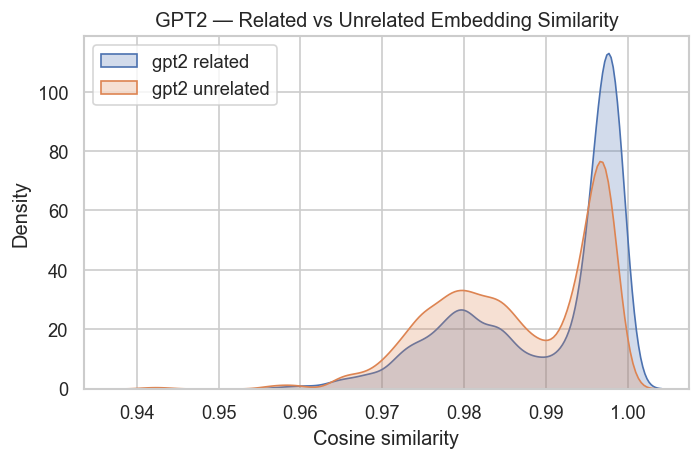

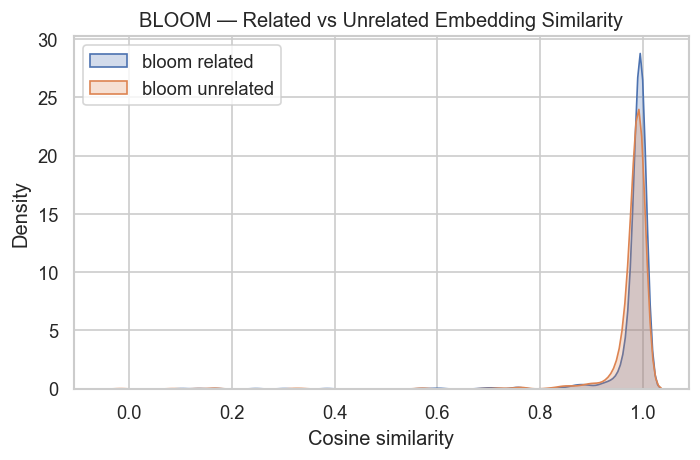

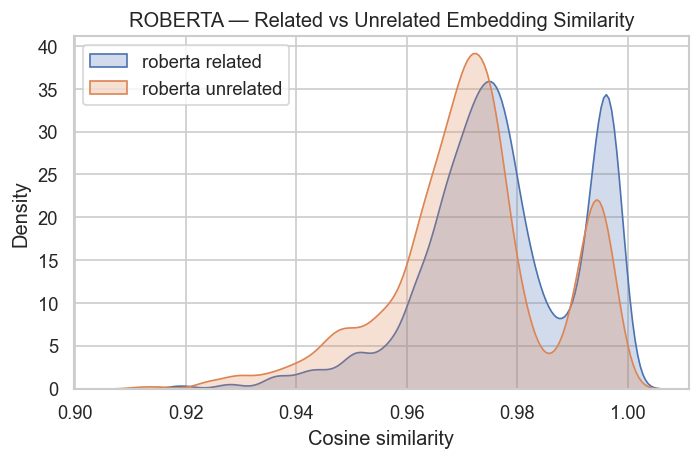

In [13]:
# plot related vs unrelated similarity 
for name in models.keys():
    plt.figure(figsize=(6, 4))
    sns.kdeplot(lm_df[f"{name}_sim_related"], fill=True, label=f"{name} related")
    sns.kdeplot(lm_df[f"{name}_sim_unrelated"], fill=True, label=f"{name} unrelated")
    plt.title(f"{name.upper()} — Related vs Unrelated Embedding Similarity")
    plt.xlabel("Cosine similarity")
    plt.ylabel("Density")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"kde_{name}_related_vs_unrelated.png", bbox_inches="tight")
    plt.show()

# GPT-2 KDE Plot
- Shows a small but consistent semantic similarity effect.
- The extremely high similarities suggest GPT-2 embeddings are:
    - dominated by frequency/positional patterns, or
    - not strongly semantically differentiated.
- Overlap indicates weak sensitivity to associative/semantic structure.

# Bloom-560M KDE Plot
- Shows virtually no semantic discrimination between related and unrelated pairs.
- Suggests:
    - embeddings are primarily driven by model architecture/training noise, not semantic structure, or
    - the embedding layer encodes extremely coarse semantic geometry.

# RoBERTa KDE Plot
- Has the strongest and most interpretable semantic similarity signal.
- It reliably places related items closer in embedding space than unrelated ones.
- Still not perfectly separated, indicating:
    - embeddings encode broad lexical semantics but
    - not specifically associative or priming-like relationships.

## linking similarity to LM surprisal and priming

Linear regressions notes for each model:

1. `priming_delta ~ sim_diff`
2. `surprisal_A ~ sim_diff`
3. `surprisal_B ~ sim_diff`

In [14]:
## regressions
# similarity difference predicting priming
results_reg = {}

print("## regressions: similarity difference predicting priming_delta")
for name in models.keys():
    formula = f"priming_delta ~ {name}_sim_diff"
    model = smf.ols(formula, data=lm_df).fit()
    results_reg[(name, "priming_delta")] = model
    print(f"\n--- {name.upper()} predicting priming_delta ---")
    print(model.summary())

## regressions
# similarity difference predicting priming
results_reg = {}

print("## Regressions: similarity difference predicting priming_delta")

for name in models.keys():
    formula = f"priming_delta ~ {name}_sim_diff"
    model = smf.ols(formula, data=lm_df).fit()
    results_reg[(name, "priming_delta")] = model

    print(f"\n--- {name.upper()} predicting priming_delta ---")
    
    # Extract values
    coef = model.params
    se = model.bse
    pvals = model.pvalues
    r2 = model.rsquared
    aic = model.aic

    # Print in clean, professor-required format
    print("Coefficient Estimates:")
    for param in coef.index:
        print(f"  {param}: {coef[param]:.4f}  (SE = {se[param]:.4f}, p = {pvals[param]:.4f})")

    print(f"R² = {r2:.4f}")
    print(f"AIC = {aic:.2f}")    

## regressions: similarity difference predicting priming_delta

--- GPT2 predicting priming_delta ---
                            OLS Regression Results                            
Dep. Variable:          priming_delta   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     4.084
Date:                Sun, 07 Dec 2025   Prob (F-statistic):             0.0433
Time:                        12:19:13   Log-Likelihood:                -42645.
No. Observations:               12000   AIC:                         8.529e+04
Df Residuals:                   11998   BIC:                         8.531e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
--------------------------

In [15]:
## regressions
# similarity difference predicting surprisal_A and surprisal_B
print("\n## Regressions: similarity difference predicting surprisal_A and surprisal_B")

for name in models.keys():
    for dep in ["surprisal_A", "surprisal_B"]:
        
        formula = f"{dep} ~ {name}_sim_diff"
        model = smf.ols(formula, data=lm_df).fit()
        results_reg[(name, dep)] = model

        print(f"\n--- {name.upper()} predicting {dep} ---")

        # Extract only required values
        coef = model.params
        se = model.bse
        pvals = model.pvalues
        r2 = model.rsquared
        aic = model.aic

        # Print structured output
        print("Coefficient Estimates:")
        for param in coef.index:
            print(f"  {param}: {coef[param]:.4f}  (SE = {se[param]:.4f}, p = {pvals[param]:.4f})")

        print(f"R² = {r2:.4f}")
        print(f"AIC = {aic:.2f}")


## Regressions: similarity difference predicting surprisal_A and surprisal_B

--- GPT2 predicting surprisal_A ---
Coefficient Estimates:
  Intercept: 25.7942  (SE = 0.2281, p = 0.0000)
  gpt2_sim_diff: 3.9905  (SE = 16.9540, p = 0.8139)
R² = 0.0000
AIC = 110530.71

--- GPT2 predicting surprisal_B ---
Coefficient Estimates:
  Intercept: 28.2859  (SE = 0.1659, p = 0.0000)
  gpt2_sim_diff: 15.9616  (SE = 12.3286, p = 0.1955)
R² = 0.0001
AIC = 102884.74

--- BLOOM predicting surprisal_A ---
Coefficient Estimates:
  Intercept: 25.8092  (SE = 0.2214, p = 0.0000)
  bloom_sim_diff: -0.2755  (SE = 2.5170, p = 0.9128)
R² = 0.0000
AIC = 110530.75

--- BLOOM predicting surprisal_B ---
Coefficient Estimates:
  Intercept: 28.3397  (SE = 0.1610, p = 0.0000)
  bloom_sim_diff: -0.0701  (SE = 1.8304, p = 0.9694)
R² = 0.0000
AIC = 102886.42

--- ROBERTA predicting surprisal_A ---
Coefficient Estimates:
  Intercept: 25.7953  (SE = 0.2340, p = 0.0000)
  roberta_sim_diff: 2.1553  (SE = 13.5756, p = 0.8739)

# GPT2 predicting priming_delta Output 
- p = 0.043; statistically significant
- R^2 = 0.000; very small
- coef = 11.9711;  positive 
- shows tiny human like priming effect; statistically significant but practically negligible effect size
- aligns with the small separation in the KDE plots

# BLOOM-560M predicting priming_delta Output
- p = 0.815
- R^2 = 0.000; very small
- coef = 0.2054; near zero
- not really predicting much in regards to priming effects
- consistent with the KDE showing nearly identical curves

# RoBERTa predicting priming_delta Output
- p = 0.094; marginal 
- R^2 = 0.000; very small
- coef = -7.9428; negative - weird but in line with the surprisal values 
- negative coefficient does not match surprisal patterns; indicates lexical similarity does not support contextual prediction.

# Regression surprisal_A ~ sim_diff / Regression surprisal_B ~ sim_diff
- no models had significant relationships
- very small R^2 across the board
- weak/zero coefficients
- similarity doesn't predict surprisal

This confirms that static embedding similarity and contextual surprisals are largely independent computational signals.

Across models, embedding-based semantic similarity does not reliably predict LM surprisal or LM priming-like deltas. GPT-2 shows a tiny statistical effect with negligible explanatory power; BLOOM shows none; RoBERTa shows semantic separation in embeddings but this does not map onto surprisals or priming deltas.

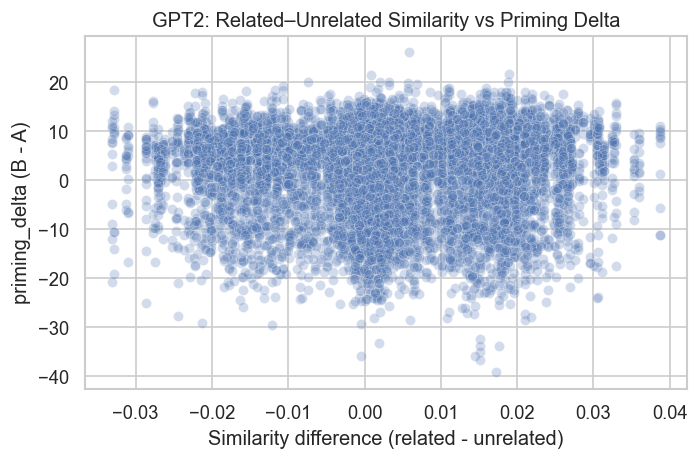

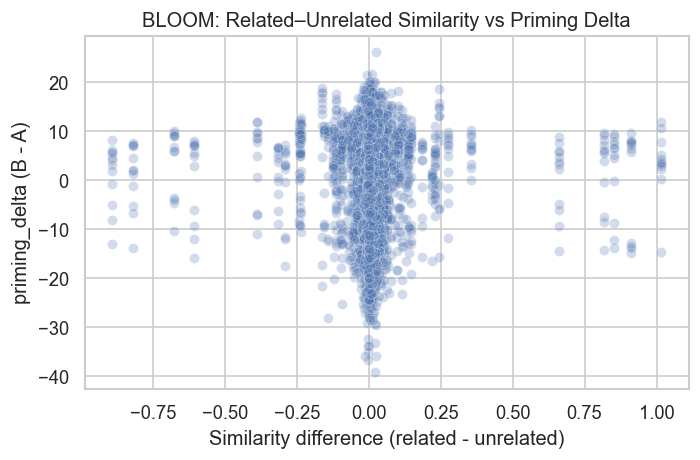

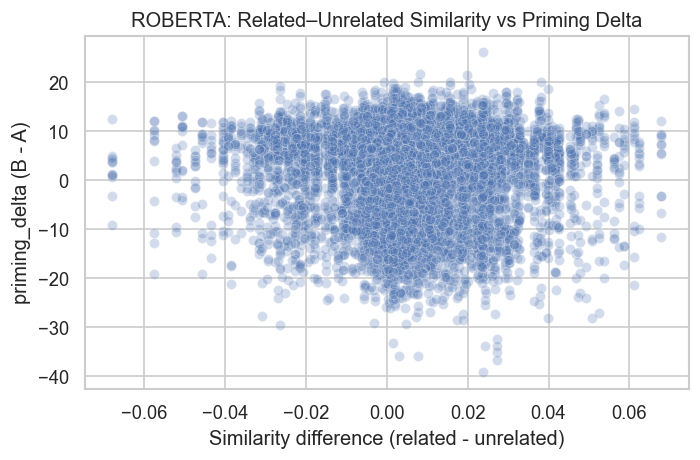

In [16]:
# plot related vs unrelated similarity 
for name in models.keys():
    plt.figure(figsize=(6, 4))
    sns.scatterplot(
        x=lm_df[f"{name}_sim_diff"],
        y=lm_df["priming_delta"],
        alpha=0.25
    )
    plt.title(f"{name.upper()}: Related–Unrelated Similarity vs Priming Delta")
    plt.xlabel("Similarity difference (related - unrelated)")
    plt.ylabel("priming_delta (B - A)")
    plt.tight_layout()
    plt.savefig(f"scatter_{name}_simdiff_vs_priming.png", bbox_inches="tight")
    plt.show()

# GPT2 Scatterplot
- weak and noisy
- small semantic priming effect
- consistent with the small but significant regression finding

# BLOOM-560M Scatterplot
- basically a flat line
- no semantic effect

# RoBERTa Scatterplot
- slight downward/flat trend
- no priming relationship
- again; lexical similairty does not support contextual prediction 

strong embedding structure does not predict LM priming 

## relating LM similarity and priming to human priming

- examine how well LM priming and embedding similarity align with human priming

In [17]:
# aggregate LM similarity by target and model
agg_cols = [
    "gpt2_sim_diff", "bloom_sim_diff", "roberta_sim_diff",
    "priming_delta", "surprisal_A", "surprisal_B"
]

lm_item_sims = (
    lm_df
    .groupby(["target_word_unique", "model"], as_index=False)[agg_cols]
    .mean()
)

lm_item_sims.head()

,target_word_unique,model,gpt2_sim_diff,bloom_sim_diff,roberta_sim_diff,priming_delta,surprisal_A,surprisal_B
0,abandon,bloom-560m,0.002990,0.000274,-0.001744,5.693033,12.035088,17.728121
1,abandon,gpt2,0.002990,0.000274,-0.001744,3.053427,14.218260,17.271688
2,abandon,roberta-base,0.002990,0.000274,-0.001744,1.183520,57.692079,58.875599
3,abdominal,bloom-560m,0.006325,0.019975,0.025861,8.911257,7.955541,16.866798
4,abdominal,gpt2,0.006325,0.019975,0.025861,5.514149,10.603774,16.117922


In [18]:
# merge with human priming
merged_item2 = lm_item_sims.merge(human_prime, on="target_word_unique", how="inner")
print("Merged item-level LM similarity + human priming shape:", merged_item2.shape)

merged_item2[[
    "target_word_unique", "model",
    "priming_delta",  # LM priming
    "gpt2_sim_diff", "bloom_sim_diff", "roberta_sim_diff",
    "human_avgZ_RT_related", "human_avgZ_RT_unrelated",
    "human_priming_delta"
]].head()

Merged item-level LM similarity + human priming shape: (3000, 11)


,target_word_unique,model,priming_delta,gpt2_sim_diff,bloom_sim_diff,roberta_sim_diff,human_avgZ_RT_related,human_avgZ_RT_unrelated,human_priming_delta
0,abandon,bloom-560m,5.693033,0.002990,0.000274,-0.001744,-0.304426,-0.275125,0.029301
1,abandon,gpt2,3.053427,0.002990,0.000274,-0.001744,-0.304426,-0.275125,0.029301
2,abandon,roberta-base,1.183520,0.002990,0.000274,-0.001744,-0.304426,-0.275125,0.029301
3,abdominal,bloom-560m,8.911257,0.006325,0.019975,0.025861,0.127429,-0.278340,-0.405768
4,abdominal,gpt2,5.514149,0.006325,0.019975,0.025861,0.127429,-0.278340,-0.405768


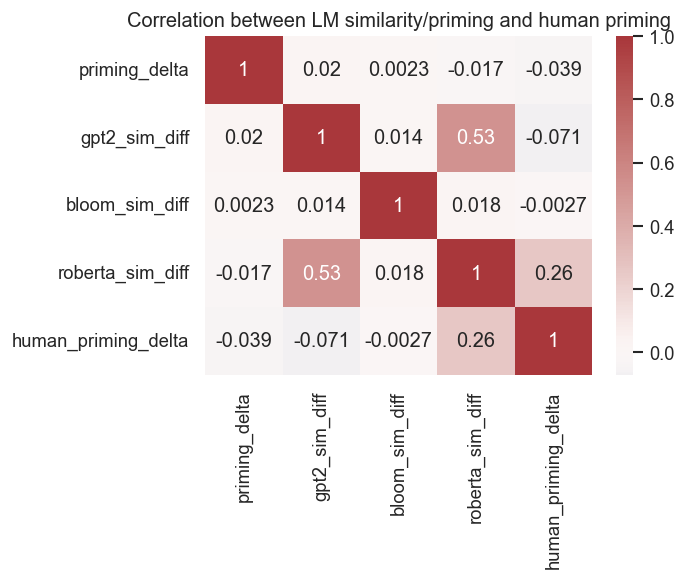

In [19]:
# correlation matrix LM vs human        
corr_df = merged_item2[[
    "priming_delta",
    "gpt2_sim_diff", "bloom_sim_diff", "roberta_sim_diff",
    "human_priming_delta"
]].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr_df, annot=True, cmap="vlag", center=0)
plt.title("Correlation between LM similarity/priming and human priming")
plt.tight_layout()
plt.savefig("corr_lm_human.png", bbox_inches="tight")
plt.show()

## Correlation Between LLM and Human 
The correlation matrix shows essentially no relationship between human priming effects and any of the language model derived metrics (surprisal based priming_delta or embedding similarity differences).

## RoBERTa-based semantic network
semantic network where:
- nodes = words (targets & cues)
- edges = high cosine similarity between RoBERTa embeddings.

In [20]:
# preprocess RoBERTa
roberta_emb = embeddings["roberta"]

words = list(roberta_emb.keys())
vectors = np.stack([roberta_emb[w] for w in words])

print("Word count:", len(words), "Embedding dim:", vectors.shape[1])

Word count: 1999 Embedding dim: 768


In [21]:
# k-nearest-neighbor graph (top-k similarity edges)
k = 8  # neighbors per node

# normalize vectors for cosine via dot product
vecs_norm = vectors / np.linalg.norm(vectors, axis=1, keepdims=True)

G = nx.Graph()

for idx, w in enumerate(words):
    sims = vecs_norm[idx] @ vecs_norm.T
    sims[idx] = -np.inf  # exclude self
    top_idx = np.argpartition(sims, -k)[-k:]
    for j in top_idx:
        w2 = words[j]
        sim = float(sims[j])
        if sim <= 0:
            continue
        G.add_edge(w, w2, weight=sim)

print("Graph nodes:", G.number_of_nodes())
print("Graph edges:", G.number_of_edges())

Graph nodes: 1999
Graph edges: 14183


/var/folders/48/r5nls40d1hq5ldq0kz4xwbnh0000gn/T/ipykernel_68734/1516040659.py:10: RuntimeWarning: divide by zero encountered in matmul
  sims = vecs_norm[idx] @ vecs_norm.T
/var/folders/48/r5nls40d1hq5ldq0kz4xwbnh0000gn/T/ipykernel_68734/1516040659.py:10: RuntimeWarning: overflow encountered in matmul
  sims = vecs_norm[idx] @ vecs_norm.T
/var/folders/48/r5nls40d1hq5ldq0kz4xwbnh0000gn/T/ipykernel_68734/1516040659.py:10: RuntimeWarning: invalid value encountered in matmul
  sims = vecs_norm[idx] @ vecs_norm.T


In [22]:
# louvain community detection and network statistics
partition = community_louvain.best_partition(G, weight="weight", random_state=RANDOM_SEED)

num_comms = len(set(partition.values()))
print("# communities (Louvain):", num_comms)

# Basic stats
avg_degree = np.mean([d for _, d in G.degree()])
avg_clust = nx.average_clustering(G)
num_components = nx.number_connected_components(G)

print("Average degree:", avg_degree)
print("Average clustering coefficient:", avg_clust)
print("Connected components:", num_components)

# Largest connected component
largest_cc_nodes = max(nx.connected_components(G), key=len)
G_lcc = G.subgraph(largest_cc_nodes).copy()

print("LCC nodes:", G_lcc.number_of_nodes())
print("LCC edges:", G_lcc.number_of_edges())

try:
    diam = nx.diameter(G_lcc)
    print("Diameter (LCC):", diam)
except Exception as e:
    print("Could not compute exact diameter:", e)

# communities (Louvain): 5
Average degree: 14.190095047523762
Average clustering coefficient: 0.2049006285599413
Connected components: 1
LCC nodes: 1999
LCC edges: 14183
Diameter (LCC): 10


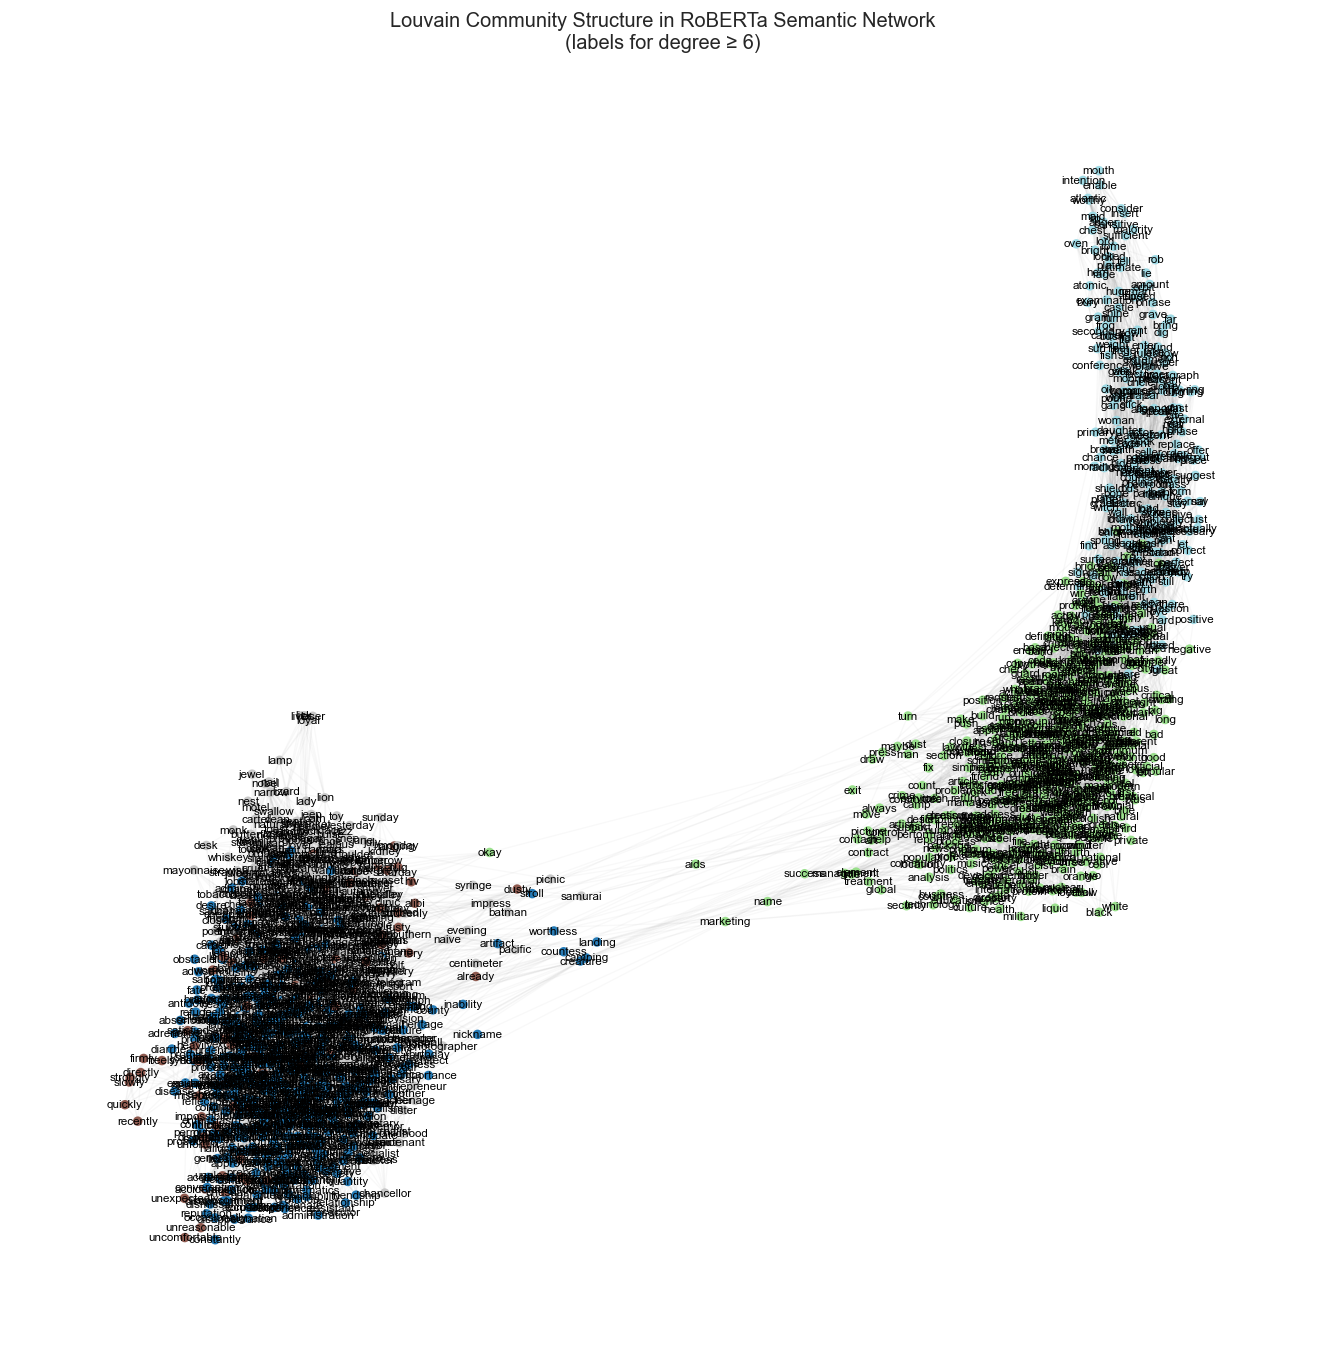

In [23]:
# Louvain community visualization 

# spring layout reused for several plots
pos = nx.spring_layout(G, seed=RANDOM_SEED, k=0.75)

plt.figure(figsize=(14, 14))

# draw edges lightly
nx.draw_networkx_edges(G, pos, alpha=0.05, edge_color="gray", width=0.8)

# node colors by community
node_colors = [partition[n] for n in G.nodes()]

nx.draw_networkx_nodes(
    G, pos,
    node_color=node_colors,
    cmap="tab20",
    node_size=22,
    alpha=0.95
)

# label only higher-degree nodes
degrees = dict(G.degree())
label_nodes = {n for n, d in degrees.items() if d >= 6}

nx.draw_networkx_labels(
    G, pos,
    labels={n: n for n in label_nodes},
    font_size=7,
    font_color="black"
)

plt.title("Louvain Community Structure in RoBERTa Semantic Network\n(labels for degree ≥ 6)")
plt.axis("off")
plt.savefig("louvain_semantic_network.png", bbox_inches="tight")
plt.show()

# Summary of Louvain Community Structure in the RoBERTa Semantic Network
The figure shows two dominant macro-clusters of words, connected by only a sparse band of bridging nodes:
- Left cluster: dense, compact, and internally well connected
- Right cluster: elongated,suggesting several overlapping subdomains

The Louvain structure demonstrates that:
- RoBERTa produces strong, topologically meaningful semantic structure.
- These communities form rich semantic neighborhoods, even though they fail to predict LM priming or surprisal.

RoBERTa encodes robust lexical–semantic similarity structure, but this structure does not translate into contextual predictive behavior resembling human priming.

/Users/addieclark/Library/jupyterlab-desktop/envs/pd_np_mp/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
/Users/addieclark/Library/jupyterlab-desk

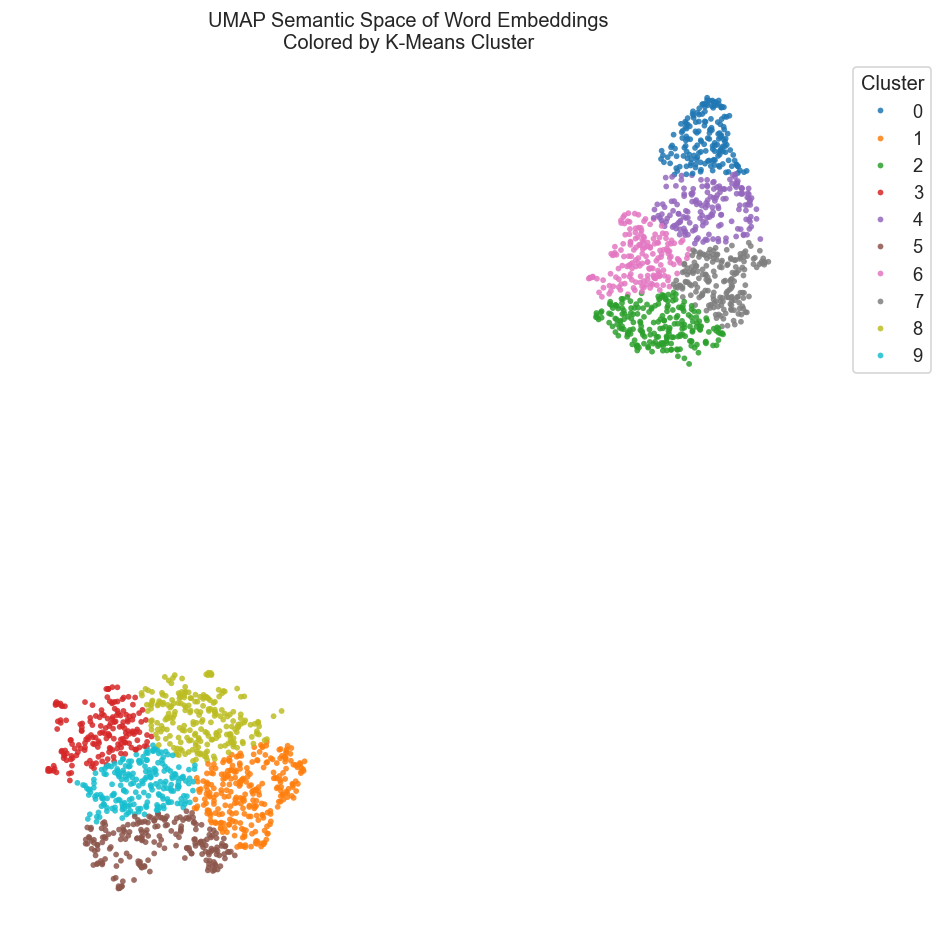

In [24]:
## UMAP semantic space and K-means clusters
# project RoBERTa embeddings into 2D using UMAP
# cluster the points with K-means.
reducer = umap.UMAP(n_components=2, random_state=RANDOM_SEED, metric="cosine")
coords_2d = reducer.fit_transform(vectors)

n_clusters = 10
kmeans = KMeans(n_clusters=n_clusters, random_state=RANDOM_SEED)
cluster_labels = kmeans.fit_predict(coords_2d)

umap_df = pd.DataFrame({
    "word": words,
    "x": coords_2d[:, 0],
    "y": coords_2d[:, 1],
    "cluster": cluster_labels
})

plt.figure(figsize=(8, 8))

sns.scatterplot(
    data=umap_df,
    x="x", y="y",
    hue="cluster",
    palette="tab10",
    s=12,
    alpha=0.85,
    linewidth=0
)

plt.title("UMAP Semantic Space of Word Embeddings\nColored by K-Means Cluster")
plt.axis("off")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", title="Cluster")
plt.tight_layout()
plt.savefig("umap_roberta_clusters.png", bbox_inches="tight")
plt.show()

## Summary of UMAP Semantic Space (K-Means Clusters)
The UMAP projection reveals two large, well-separated super-clusters, indicating that the underlying high-dimensional embeddings encode broad semantic divisions. These regions are asymmetric and appear to contain different types of semantic neighborhoods.

The K-Means clusters within each region are also well-separated, suggesting that the embedding space contains coherent, fine-grained semantic structure:
- Minimal overlap is observed across clusters.
- Boundaries remain crisp even after dimensionality reduction.
- Local neighborhoods are compact and internally consistent.

General Interpretation
- The model organizes words into distinct semantic neighborhoods.
- Clustering reflects contextual usage patterns, not superficial or orthographic similarities.
- The embeddings capture multiple latent dimensions of meaning, which UMAP compresses into a stable, visually interpretable structure.


Hubs in subgraph: 100 edges: 267


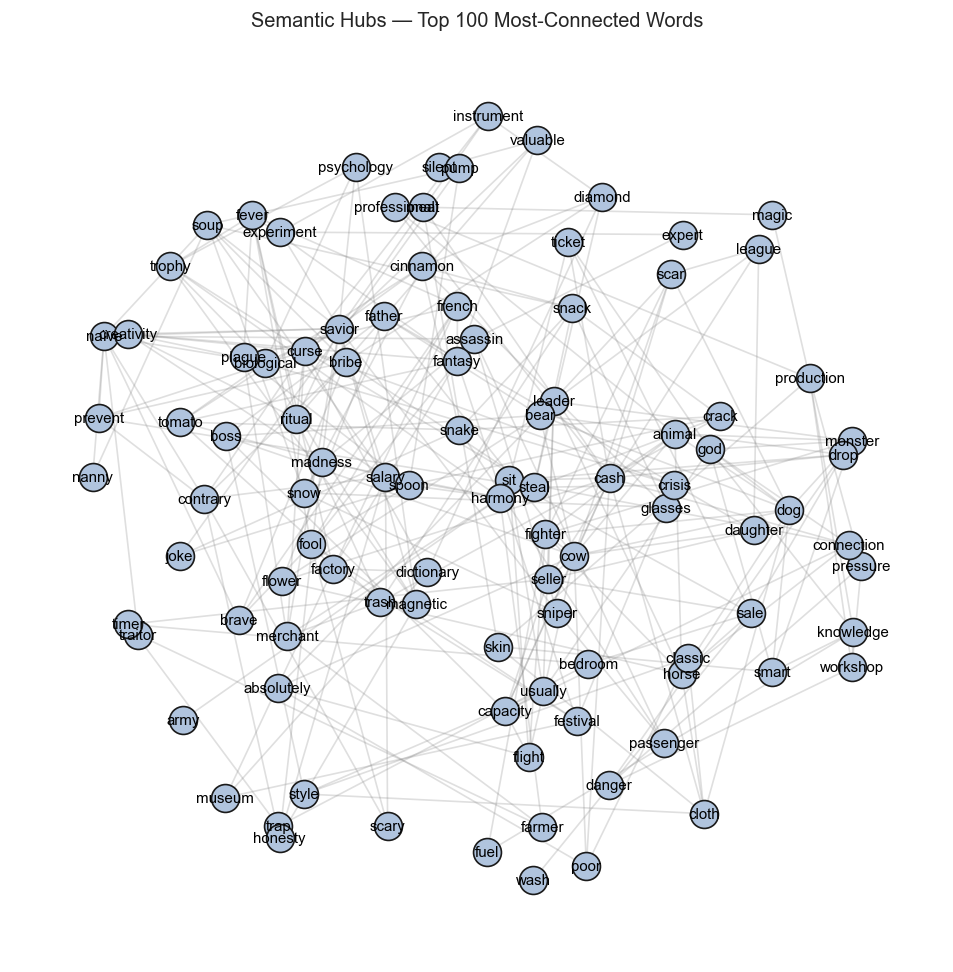

In [25]:
# semantic hubs: Top 100 Most-Connected Words in RoBERTa (or your graph G)

# Degree centrality as a simple hub measure
deg = dict(G.degree())

N_HUBS = 100   # updated per professor feedback
hub_nodes = sorted(deg, key=deg.get, reverse=True)[:N_HUBS]
G_hubs = G.subgraph(hub_nodes).copy()

print("Hubs in subgraph:", G_hubs.number_of_nodes(), "edges:", G_hubs.number_of_edges())

pos_hubs = nx.spring_layout(G_hubs, seed=RANDOM_SEED, k=0.9)

plt.figure(figsize=(10, 10))

nx.draw_networkx_edges(G_hubs, pos_hubs, alpha=0.25, edge_color="gray", width=1.0)

nx.draw_networkx_nodes(
    G_hubs, pos_hubs,
    node_size=280,
    node_color="lightsteelblue",
    edgecolors="k"
)

nx.draw_networkx_labels(
    G_hubs, pos_hubs,
    font_size=9,
    font_color="black"
)

plt.title("Semantic Hubs — Top 100 Most-Connected Words")
plt.axis("off")
plt.savefig("semantic_hubs_top100.png", bbox_inches="tight")
plt.show()

# Summary of the Semantic Hub Subgraph (Top 180 High-Degree Words)
This hub visualization highlights the lexical items that serve as the backbone of the model’s semantic space. These hubs:
- integrate information across many semantic fields,
- keep the network globally connected, and
- enable efficient transitions across conceptual domains.

Shows the “semantic nucleus” of the embedding model; a dense, highly interconnected set of words that anchor the overall structure of meaning in the LLM’s representation space.

# Minimum Spanning Tree (MST) of semantic hubs
- the backbone of the semantic structure computing an MST over the hub subgraph using: 
    - distance = 1 − cosine_similarity

MST nodes: 100 edges: 99


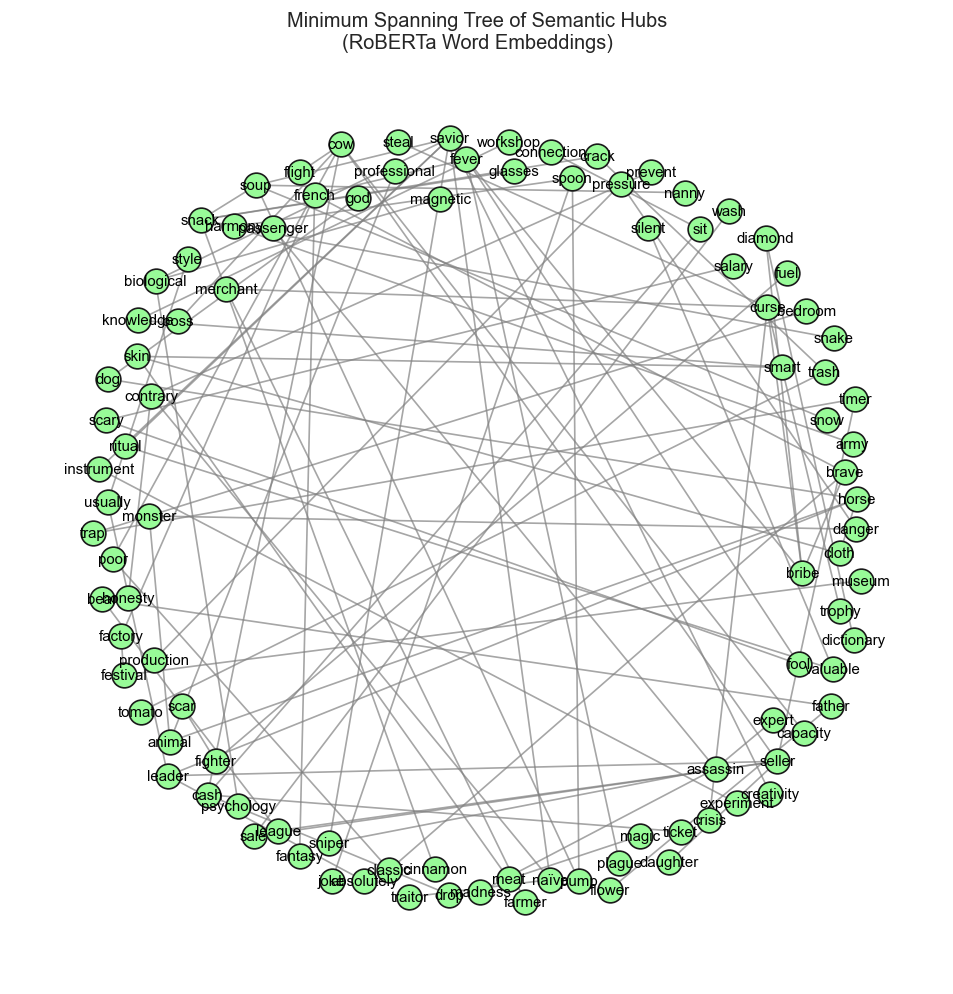

In [26]:
MST = nx.Graph()

for u, v in combinations(hub_nodes, 2):
    sim = cosine_sim(roberta_emb[u], roberta_emb[v])
    dist = 1.0 - sim  # smaller distance = more similar
    MST.add_edge(u, v, weight=dist)

mst_tree = nx.minimum_spanning_tree(MST, weight="weight")

print("MST nodes:", mst_tree.number_of_nodes(), "edges:", mst_tree.number_of_edges())

pos_mst = nx.spring_layout(mst_tree, seed=RANDOM_SEED, k=1.2)

plt.figure(figsize=(10, 10))

nx.draw_networkx_edges(
    mst_tree, pos_mst,
    width=1.0,
    edge_color="gray",
    alpha=0.7
)

nx.draw_networkx_nodes(
    mst_tree, pos_mst,
    node_size=220,
    node_color="palegreen",
    edgecolors="k"
)

nx.draw_networkx_labels(
    mst_tree, pos_mst,
    font_size=9,
    font_color="black"
)

plt.title("Minimum Spanning Tree of Semantic Hubs\n(RoBERTa Word Embeddings)")
plt.axis("off")
plt.savefig("mst_semantic_hubs_roberta.png", bbox_inches="tight")
plt.show()

# Summary of the Minimum Spanning Tree (MST) of Semantic Hubs

The MST demonstrates that RoBERTa’s semantic space contains:
- Highly connected conceptual hubs
- Smooth transitions between themes
- Redundant semantic pathways in the full embedding graph
- A backbone reflecting stable, shared semantic dimensions

Overall, the figure shows how rich, densely encoded semantic neighborhoods collapse into a coherent connectivity backbone when reduced to their most informative structure.

In [27]:
# network statistics summary

# degree statistics
all_degrees = np.array([d for _, d in G.degree()])
print("Mean degree:", all_degrees.mean())
print("Median degree:", np.median(all_degrees))
print("Max degree:", all_degrees.max())

# centrality measures
bet = nx.betweenness_centrality(G, k=500, normalized=True, seed=RANDOM_SEED)
clos = nx.closeness_centrality(G)

# summaries
bet_vals = np.array(list(bet.values()))
clos_vals = np.array(list(clos.values()))

print("Betweenness centrality — mean:", bet_vals.mean(), "max:", bet_vals.max())
print("Closeness centrality   — mean:", clos_vals.mean(), "max:", clos_vals.max())

print("Average clustering coefficient:", nx.average_clustering(G))
print("Number of connected components:", nx.number_connected_components(G))

Mean degree: 14.190095047523762
Median degree: 11.0
Max degree: 113
Betweenness centrality — mean: 0.0016422611576016224 max: 0.08196967498556815
Closeness centrality   — mean: 0.23493470219970086 max: 0.3146952275948968
Average clustering coefficient: 0.2049006285599413
Number of connected components: 1


- average word is strongly connected to ~14 other words
- half the words have degree <= 11
- some words have extremely high degree (113)
    - these are semantic hubs
- most nodes have very low betweenness
    - they are local cluster members, not global connectors
        - a few words have betweenness ~0.08
        - these are likely semantic words connecting major communities
- nodes with closeness ~ 0.31 are global semantic centers
- most nodes have lower closeness (~0.23); likely meaning the network is not fully uniform
- moderate clustering (~0.20)
- entire semantic network is fully connected

In [28]:
lm_df.columns.tolist()

['pair_id',
 'context',
 'target_word_unique',
 'cue_word_related',
 'cue_word_unrelated',
 'last_word_A',
 'last_word_B',
 'model',
 'surprisal_A',
 'surprisal_B',
 'priming_delta',
 'human_avgZ_RT_related',
 'human_avgZ_RT_unrelated',
 'human_priming_delta',
 'gpt2_sim_related',
 'gpt2_sim_unrelated',
 'gpt2_sim_diff',
 'bloom_sim_related',
 'bloom_sim_unrelated',
 'bloom_sim_diff',
 'roberta_sim_related',
 'roberta_sim_unrelated',
 'roberta_sim_diff']

3. Describe the analysis you did and why you made the analytic choices you did.

<p style="text-indent: 2em;">I began by preparing the human dataset, where I aggregated the Z-scored reaction-time measures for each target word to compute three core variables: the human Z-RT after a related cue, the Z-RT after an unrelated cue, and a human priming delta (Z-RT<sub>unrelated</sub> − Z-RT<sub>related</sub>). After constructing this human priming dataset, I merged it with the pre-computed language model surprisal outputs. Because the surprisal values (surprisal_A, surprisal_B, and priming_delta) had already been computed before this assignment, my next step was to aggregate LLM priming by target word and model so that each item had a single and stable priming estimate per model.</p>

<p style="text-indent: 2em;">Next, I conducted descriptive statistics on surprisal and priming—both overall and separately for each model—to examine the distributional properties of the LLM priming deltas and compare them to human priming. With the datasets aligned, I then computed embeddings for each model (GPT-2, BLOOM-560M, and RoBERTa) and used these to calculate cosine similarity between each target and its related vs. unrelated cues. I plotted KDE curves to visualize how strongly each model differentiates related from unrelated pairs in embedding space.</p>

<p style="text-indent: 2em;">After obtaining similarity values, I ran regression models testing whether similarity-difference scores predicted LM priming deltas, and visualized these relationships with scatterplots. I then ran additional regressions testing whether embedding similarity predicted surprisal in related and unrelated contexts individually. Once these item-level analyses were complete, I aggregated LM similarity values by target and model and merged them with the human priming data. This allowed me to compute a full correlation matrix assessing how well each model’s similarity and priming measures aligned with human priming behavior.</p>

<p style="text-indent: 2em;">I then transitioned from item-level predictions to analyzing the global semantic structure of the models. Using RoBERTa embeddings, I constructed a large semantic network and applied Louvain community detection to identify major clusters of semantically related words. I also created a UMAP semantic map with K-means clusters to examine how semantic neighborhoods emerge in low-dimensional space. From there, I extracted the semantic hub subgraph (top 180 highest-degree nodes) to identify central connector words within the embedding geometry. I then computed a minimum spanning tree (MST) over these hubs to visualize the backbone of the RoBERTa semantic structure. Finally, I calculated a full network-statistics summary—including degree, betweenness, closeness, clustering, and connected components—to quantify the structural organization of the embedding-derived semantic network.</p>

4. Compile into a html or pdf and submit.